In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, '../../../src/')
import DoubleLayerWithHoles as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Inside0,Inside1,Solution0,Eigenvalues.1,Eigenvectors0.1,Inside0.1,Inside1.1,Solution0.1,...,Eigenvalues.3,Eigenvectors0.3,Inside0.3,Inside1.3,Solution0.3,Eigenvalues_higher_precision,Eigenvectors_higher_precision0,Inside_higher_precision0,Inside_higher_precision1,Solution_higher_precision0
0,(5.573459755981792+1.4140024256280408e-08j),(-0.00027681416865279606-0.000217957059891547j),-0.51250,-0.82,(6.4214593557390865e-06+6.222722356109447e-06j),(7.954194249834582+4.8504369269327e-06j),(-0.002279319150411157+0.0008417722122750894j),-0.51250,-0.82,(0.0002995966661099576+0.00030368375106895433j),...,(8.265224860376353+4.161429389415439e-06j),(-0.0009224686134728041+0.003124866753859796j),-0.51250,-0.82,(-7.527265335443146e-05+0.0002292856526753084j),(7.954194249834582+4.8504369269327e-06j),(-0.002279319150411157+0.0008417722122750894j),-0.50225,-0.861,(7.727934883372447e-06+2.0419283786767342e-05j)
1,NaN,(-0.00027644735436341326-0.00016630637774681122j),-0.46125,-0.82,(2.301732444992232e-05+2.252837121964469e-05j),NaN,(-0.0021341563937293693+0.0018686269755494385j),-0.46125,-0.82,(0.0010725391629360476+0.001090750080583948j),...,NaN,(0.001253973345439785+0.0024102456532560847j),-0.46125,-0.82,(-0.0002227885630970124+0.000842954190692459j),(7.987345334510363+4.664111237673296e-06j),(-0.0021341563937293693+0.0018686269755494385j),-0.49200,-0.861,(5.421619077056227e-05+6.0422604598704514e-05j)
2,NaN,(-0.0002808452684497957-9.368192119212829e-05j),-0.41000,-0.82,(3.3551941819715794e-05+3.290344245952023e-05j),NaN,(-0.002341971185024461+0.0029584247834438413j),-0.41000,-0.82,(0.001524730297114442+0.0015516329143289579j),...,NaN,(0.0035346993280738793+0.0021625598847421932j),-0.41000,-0.82,(-0.00020963421272334956+0.001247321219142488j),(7.987345334595028+4.663860699827622e-06j),(-0.002341971185024461+0.0029584247834438413j),-0.48175,-0.861,(7.829209808204031e-05+7.594331998055093e-05j)
3,NaN,(-0.00028450479746075345-4.477885698836388e-05j),-0.35875,-0.82,(4.2297631729536146e-05+4.1470923442147044e-05j),NaN,(-0.002617130406387994+0.0035689586522346527j),-0.35875,-0.82,(0.0018233846355194157+0.0018554360717000134j),...,NaN,(0.004812685633310609+0.0021891499684165102j),-0.35875,-0.82,(-8.434421388582082e-05+0.0015658215124980043j),NaN,(-0.002617130406387994+0.0035689586522346527j),-0.47150,-0.861,(9.727323524603027e-05+9.321311449340172e-05j)
4,NaN,(-0.00029103176668569147+4.786297031111919e-05j),-0.30750,-0.82,(5.1508026496864905e-05+5.051210100071561e-05j),NaN,(-0.003316121356470215+0.004553492532585263j),-0.30750,-0.82,(0.002050600460196223+0.0020868053000681515j),...,NaN,(0.006814839461080576+0.002436835747907377j),-0.30750,-0.82,(0.00011662791410231273+0.0018538919472085478j),NaN,(-0.003316121356470215+0.004553492532585263j),-0.46125,-0.861,(0.00011325195821428025+0.0001113373284120072j)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23106,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.46125,0.861,(0.00011325195801807088+0.00011133732816513697j)
23107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.47150,0.861,(9.727323507367899e-05+9.321311424714037e-05j)
23108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.48175,0.861,(7.829209793559127e-05+7.59433197338906e-05j)
23109,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.49200,0.861,(5.421619065123975e-05+6.042260435044824e-05j)


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
# Discretization
faces = np.array([105,105])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

#Parameters for the hexagon
n_gon_hexagon = 6
side_length = 1
R = side_length/(2*np.sin(np.pi/n_gon_hexagon))
xm = 0
ym = 0
rot = 0
hexagon = DL.create_polygon(n_gon_hexagon,R,xm,ym,rot,n[0])

# Parameters for the triangle
n_gon_triangle = 3
height = 6/27
R = height*2/3
distance = 13/27
angles = np.linspace(0,2*np.pi, n_gon_hexagon, endpoint=False)

xm = distance*np.cos(angles)
ym = distance*np.sin(angles)

rot1 = 2*np.pi/3
rot2 = 2*np.pi/(3*2)
hexagon_triangles = np.empty(n_gon_hexagon+1, dtype=object)
hexagon_triangles[0] = hexagon

# Create 6 triangles at the correct positions
for i in range(n_gon_hexagon):
    if np.mod(i,2) == 0:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot1,n[1])
    else:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot2,n[1])
    tringle_flip = np.flip(triangle_temp,1)
    hexagon_triangles[i+1] = tringle_flip

# Stack all the boundaries together
vi = np.copy(hexagon_triangles)
collocation_nodes = np.empty(n_gon_hexagon+1, dtype= object)
for i in range(n_gon_hexagon+1):
    collocation_nodes[i] = DL.create_collocation_nodes(vi[i],alpha) 

In [7]:
vi_with_end_point = np.copy(vi)
for i in range(n_gon_hexagon+1):
    vi_with_end_point[i] = np.append(vi_with_end_point[i],vi[i][:,:1],axis = 1)

(np.float64(-1.1000000000000003),
 np.float64(1.1000000000000003),
 np.float64(-0.9526279441628832),
 np.float64(0.9526279441628829))

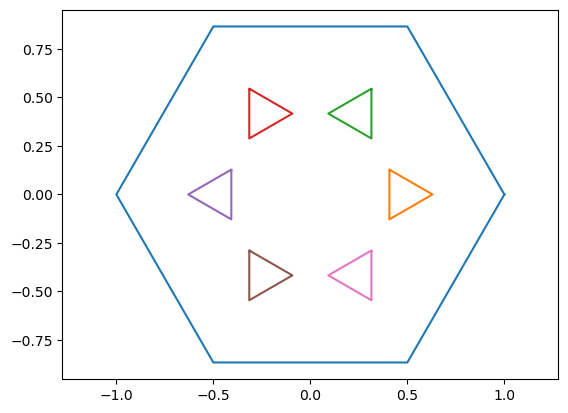

In [8]:
for i in range(n_gon_hexagon+1):
    plt.plot(vi_with_end_point[i][0,:], vi_with_end_point[i][1,:])
plt.axis('equal')

In [9]:
def ray_tracing_in_holes(boundary, xmid, ymid):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    x_start : float
        Start value of a square in x-direction.
    x_end : float
        End value of a square in x-direction.
    x_steps : int
        Number of points in x-direction that should be checked to be inside the given domain without holes.
    y_start : float
        Start value of a square in y-direction.
    y_end : float
        End value of a square in y-direction.
    y_steps : int
        Number of points in y-direction that should be checked to be inside the given domain without holes.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [17]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'(5.573459755981792+1.4140024256280408e-08j)'

In [18]:
5.573459755981792*5.573459755981792

31.06345365154862

In [19]:
eigenvalues = inside_solution['Eigenvalues_higher_precision'][0]
eigenvalues

'(7.954194249834582+4.8504369269327e-06j)'

In [20]:
7.954194249834582*7.954194249834582

63.269206164101526

In [21]:
xy_inside = inside_solution[['Inside_higher_precision0', 'Inside_higher_precision1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [22]:
sol = inside_solution['Solution_higher_precision0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

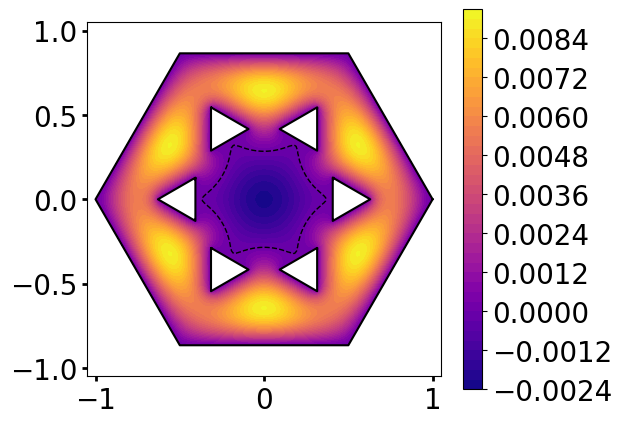

In [25]:
x_inside = xy_inside[0,:]
y_inside = xy_inside[1,:]
real_sol = np.real(sol)
vmin_sol=np.sort(real_sol)[2]
vmax_sol=np.sort(real_sol)[-3]
# Triangulation
triang = tri.Triangulation(x_inside, y_inside)

# Mask
xmid = x_inside[triang.triangles].mean(axis=1)
ymid = y_inside[triang.triangles].mean(axis=1)
mask1 = ray_tracing_in_holes(np.array([vi_with_end_point[0]]), xmid, ymid)
mask2 = ray_tracing_in_holes(np.array([vi_with_end_point[1]]), xmid, ymid)
mask3 = ray_tracing_in_holes(np.array([vi_with_end_point[2]]), xmid, ymid)
mask4 = ray_tracing_in_holes(np.array([vi_with_end_point[3]]), xmid, ymid)
mask5 = ray_tracing_in_holes(np.array([vi_with_end_point[4]]), xmid, ymid)
mask6 = ray_tracing_in_holes(np.array([vi_with_end_point[5]]), xmid, ymid)
mask7 = ray_tracing_in_holes(np.array([vi_with_end_point[6]]), xmid, ymid)


mask1_inv = ~mask1
mask = mask1_inv | mask2 | mask3 | mask4 | mask5 | mask6 | mask7
triang.set_mask(mask)
# Kontur-Plot
plt.rcParams.update({'font.size':20})
plt.tick_params(axis='both', width=2)
plt.tricontourf(triang, real_sol, cmap='plasma',levels= 40)#, vmin=vmin_sol, vmax=vmax_sol)
cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=20)
plt.tricontour(triang, real_sol, colors='black', levels = [0], linestyles = 'dashed', linewidths = 1)

for i in range(n_gon_hexagon+1):
    plt.plot(vi_with_end_point[i][0,:],vi_with_end_point[i][1,:], 'black')

plt.axis('square')
plt.xlim(-1.05,1.05)
plt.ylim(-1.05,1.05)
plt.tight_layout()
plt.savefig('hexagon_six_triangles_13_24.eps', format="eps")
plt.show()

In [14]:
eigenvalues = inside_solution['Eigenvalues.2'][0]
eigenvalues

'(7.987345334510363+4.664111237673296e-06j)'

In [15]:
7.987345334510363*7.987345334510363

63.79768549272446